# Report 4 - Classification với nhãn AI silver

480 review từ nguồn tự crawl của EDA đã được AI đọc và gán theo nội dung, metadata rating/source/region/split ẩn khỏi bản đọc. 450 review dùng cho ba lớp, 26 mixed và 4 uncertain loại. Nhãn đã khóa trước train. **Không phải nhãn người/gold.** Notebook tái lập train/evaluation, không tái tạo hoặc sửa nhãn từ rating hay prediction.

Kết quả bản 15/11: validation chọn Logistic Regression, test accuracy 90%, macro-F1 0,598; neutral F1=0. Các ô dưới tính lại từ dữ liệu đã khóa.

## 1. Đọc nhãn đã khóa và kiểm tra nguồn
Mở bằng Python `.venv-report4`. Cần folder nhãn và run gốc có trong gói nộp; không cần crawl/MinIO hoạt động.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/modeling/classification.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.modeling import classification as c
ANN=ROOT/'data/annotations/report4_ai_20261115'
LOCK=json.loads((ANN/'annotation_lock.json').read_text(encoding='utf-8'))
assert c.sha256(ANN/'annotations.jsonl')==LOCK['annotations_sha256']
labels=c.read_rows(ANN/'annotations.jsonl')
c.validate_annotations(labels)
display(pd.Series(LOCK['label_counts'],name='count').to_frame())

,count
positive,342
negative,86
neutral,22
mixed,26
uncertain,4


## 2. Xem bằng chứng gán nhãn
Nhãn AI có confidence/reason/text hash. File blind ban đầu chỉ có ID/text/hash; nhãn không suy bằng sao. Các quyết định M/X được giữ lại để audit.

In [2]:
blind=c.read_rows(ANN/'blind_sample.jsonl')
assert all(set(r)=={'blind_id','text','text_sha256'} for r in blind)
display(pd.DataFrame(labels)[['blind_id','text','sentiment','confidence','reason','label_source']].head(8))
print('accepted:',len(c.training_rows(labels)))

,blind_id,text,sentiment,confidence,reason,label_source
0,1,"Lẩu thái ngon nên thử,nhân viên lễ phép",positive,high,dominant_praise_or_recommendation,ai_reviewed
1,2,Anh Thanh đây. Anh thích nhất món sườn cốt lết...,positive,high,dominant_praise_or_recommendation,ai_reviewed
2,3,Đồ ăn ngon nhân viên phương anh phục vụ nhiệt ...,positive,high,dominant_praise_or_recommendation,ai_reviewed
3,4,"Quán được giới thiệu trên nhiều diễn đàn, nay ...",positive,high,dominant_praise_or_recommendation,ai_reviewed
4,5,"15k một đĩa, siêu ngon hụ hụ. Mà hình như ngày...",positive,high,dominant_praise_or_recommendation,ai_reviewed
5,6,"Đề nghị quán xem lại cách rửa rau, có vẻ như k...",negative,high,dominant_dissatisfaction,ai_reviewed
6,7,"Quán đẹp, phục vục tốt, không gian quán ổn một...",positive,high,dominant_praise_or_recommendation,ai_reviewed
7,8,Tomyum sữa ngon Còn vị kia quá bt Chè thái tạm...,neutral,medium,factual_query_or_average_no_clear_polarity,ai_reviewed


accepted: 450


## 3. Chạy lại pipeline
Nhóm cùng quán/trùng gần trước split 60/20/20. TF-IDF classifier chỉ fit train. So Logistic/SVM theo validation macro-F1; CV 5 fold chỉ train để chẩn đoán; test chấm model đã chọn và Dummy. Giữ nguyên nhãn và tham số.

In [3]:
from datetime import datetime
OUT=ROOT/'report4_outputs'/('classification_notebook_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
c.train(ANN,OUT,42)
manifest=json.loads((OUT/'manifest.json').read_text(encoding='utf-8'))
print('selected:',manifest['selected_model'])
summary=pd.read_csv(OUT/'metrics_summary.csv')
display(summary)

{
  "mode": "ai_silver_holdout",
  "sampled": 480,
  "accepted": 450,
  "excluded": 30,
  "partition_counts": {
    "train": 270,
    "validation": 90,
    "test": 90
  },
  "label_counts": {
    "positive": 342,
    "negative": 86,
    "neutral": 22
  },
  "selected_model": "logistic_regression"
}
{
  "test": {
    "logistic_regression": {
      "n": 90,
      "accuracy": 0.9,
      "macro_f1": 0.5977710233029382,
      "confusion_matrix": [
        [
          15,
          0,
          3
        ],
        [
          0,
          0,
          4
        ],
        [
          2,
          0,
          66
        ]
      ],
      "classes": {
        "negative": {
          "precision": 0.8823529411764706,
          "recall": 0.8333333333333334,
          "f1-score": 0.8571428571428571,
          "support": 18.0
        },
        "neutral": {
          "precision": 0.0,
          "recall": 0.0,
          "f1-score": 0.0,
          "support": 4.0
        },
        "positive": {
    

,partition,model,n,accuracy,macro_f1,selected_by_validation
0,train,dummy_most_frequent,270,0.759259,0.287719,False
1,train,logistic_regression,270,1.000000,1.000000,True
2,train,linear_svm,270,1.000000,1.000000,False
3,validation,dummy_most_frequent,90,0.766667,0.289308,False
4,validation,logistic_regression,90,0.833333,0.497307,True
5,validation,linear_svm,90,0.833333,0.486887,False
6,test,logistic_regression,90,0.900000,0.597771,True
7,test,dummy_most_frequent,90,0.755556,0.286920,False


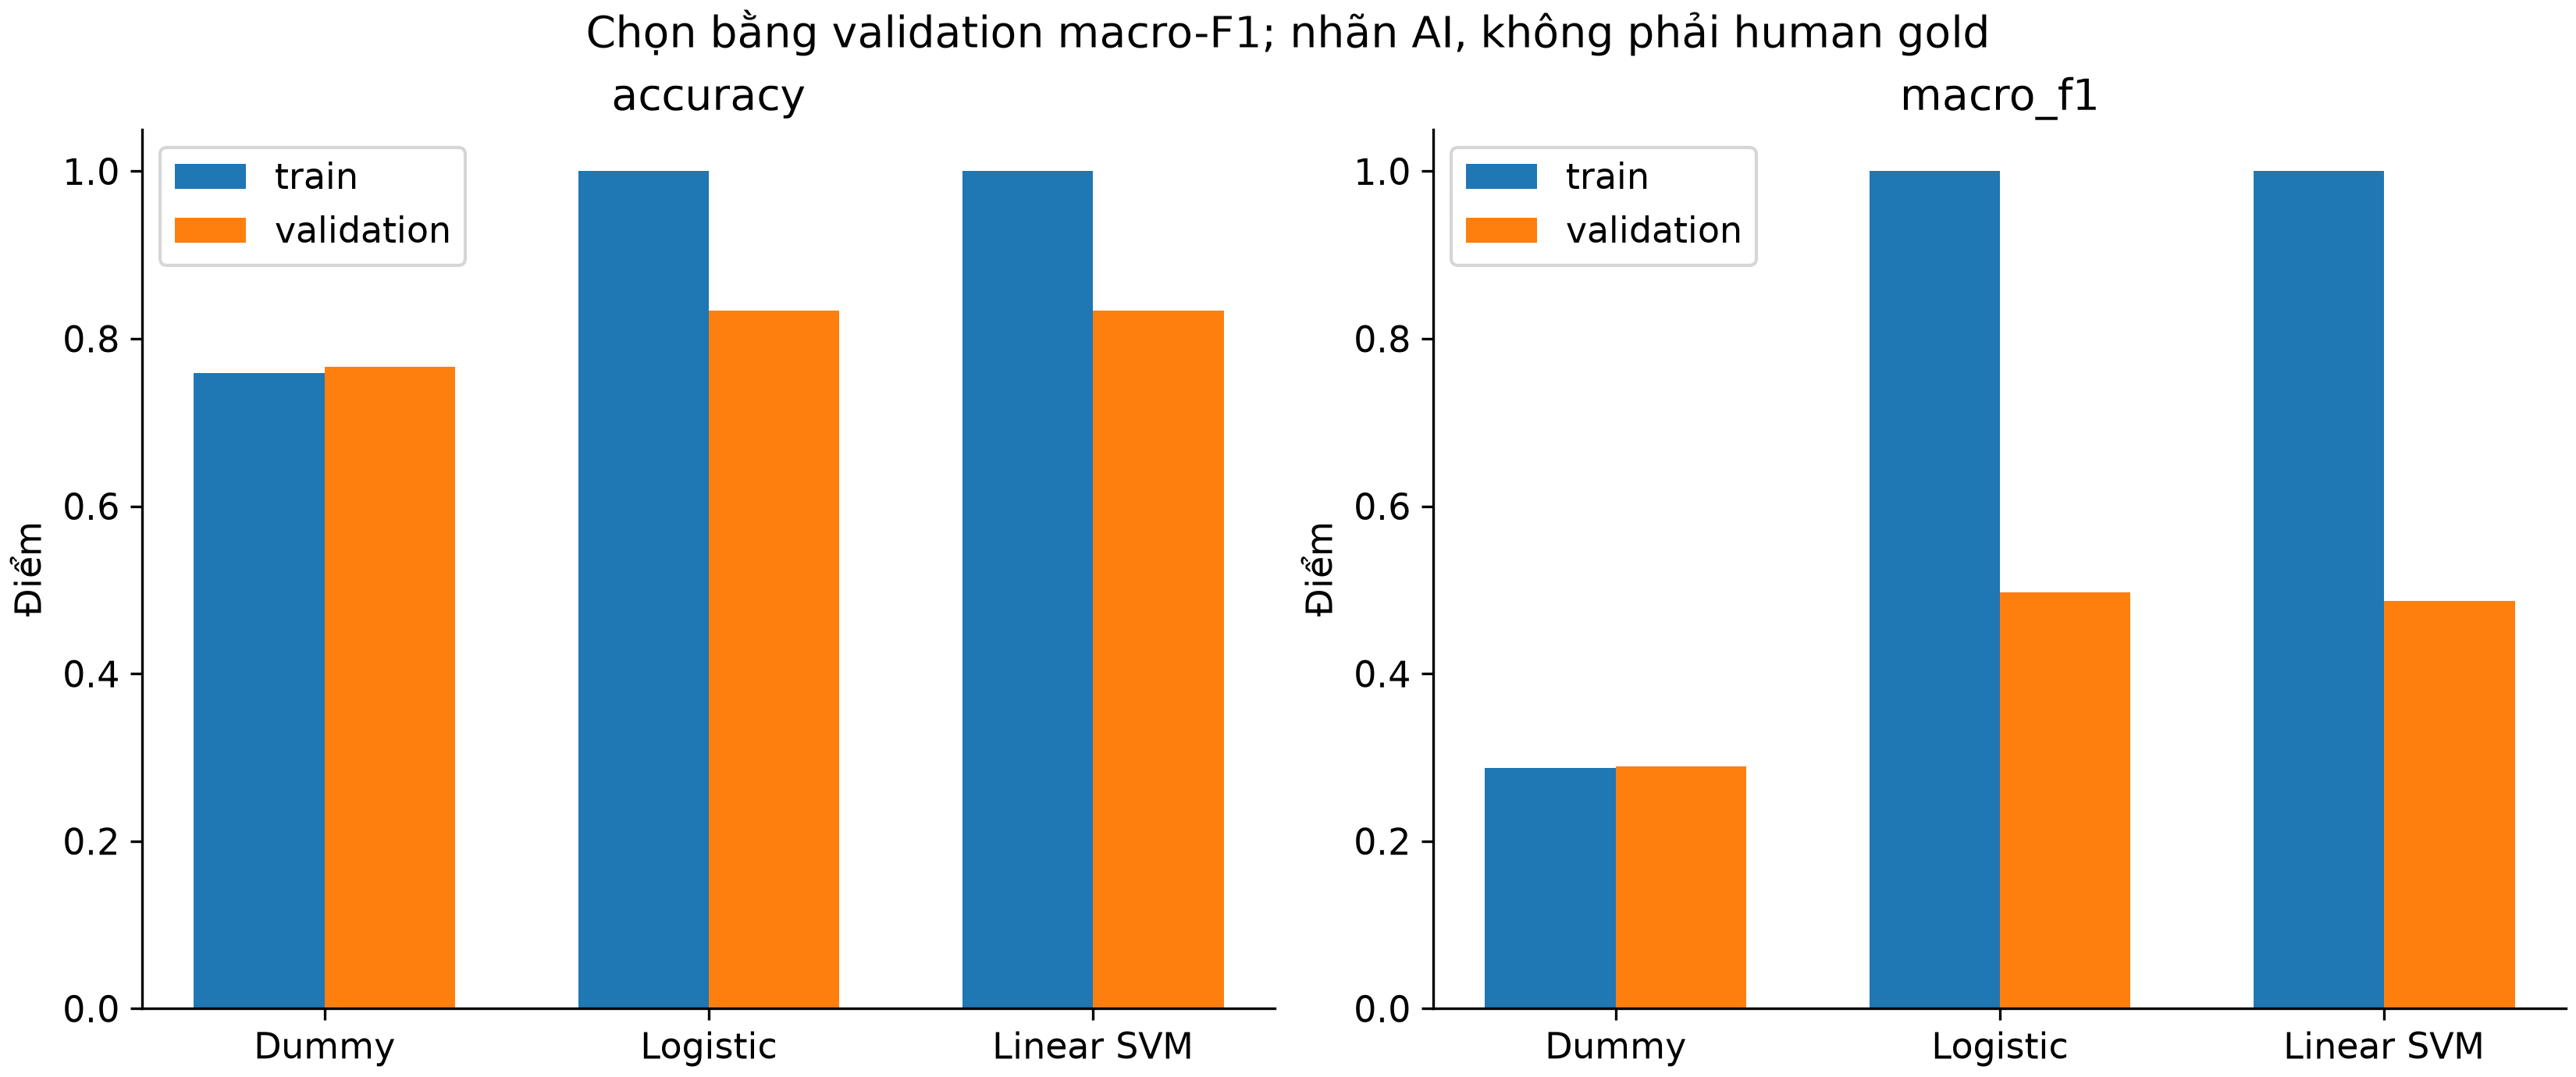

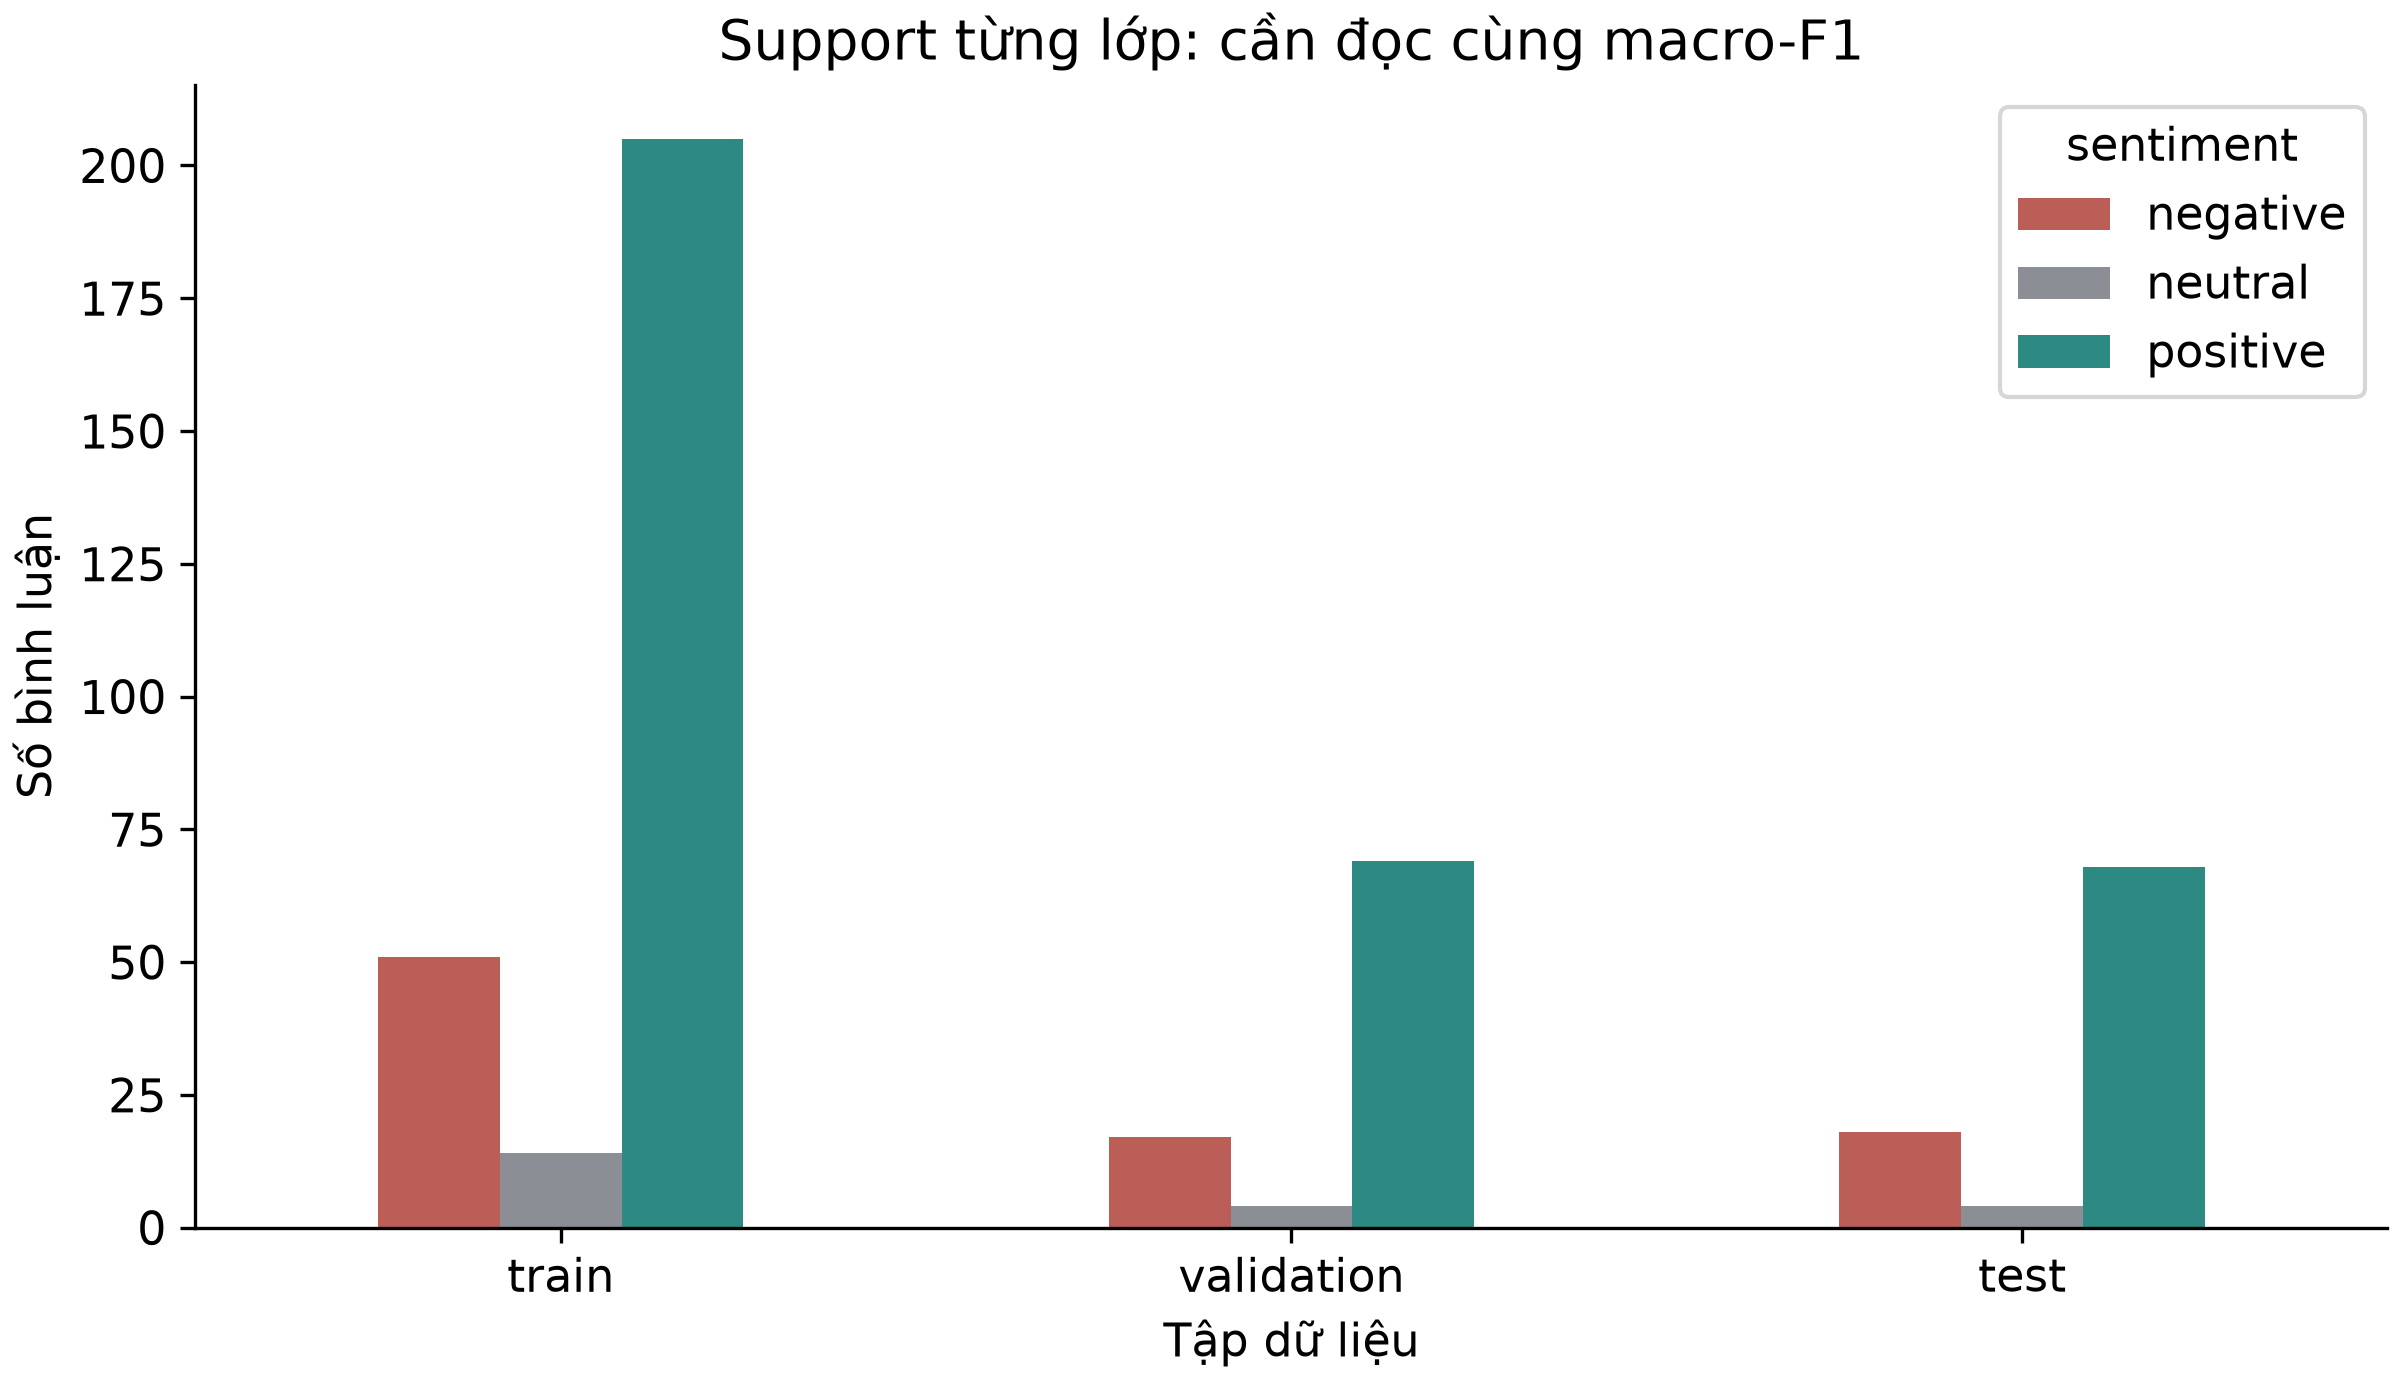

In [4]:
display(Image(filename=str(OUT/'fig_class_model_comparison.png'),width=900))
display(Image(filename=str(OUT/'fig_class_support.png'),width=800))

## 4. Công thức và thay số từ confusion matrix
Rows=nhãn AI tham chiếu; columns=prediction. Accuracy=trace(C)/sum(C). Precision=TP/(TP+FP), Recall=TP/(TP+FN), F1=2TP/(2TP+FP+FN). Macro-F1 lấy trung bình 3 lớp kể cả neutral F1=0.

,class,TP,FP,FN,F1
0,negative,15,2,3,0.857143
1,neutral,0,0,4,0.000000
2,positive,66,7,2,0.936170


accuracy= 81 / 90 = 0.9
macro-F1= 0.5977710233029382
Bootstrap intervals: {'repetitions': 2000, 'unit': 'leakage_group', 'seed': 42, 'accuracy_ci95': [0.8333333333333334, 0.9555555555555556], 'macro_f1_ci95': [0.5346291273166388, 0.6391301575072523], 'meaning': 'Conditional on this sample and one AI rubric; excludes label uncertainty and source selection bias.'}


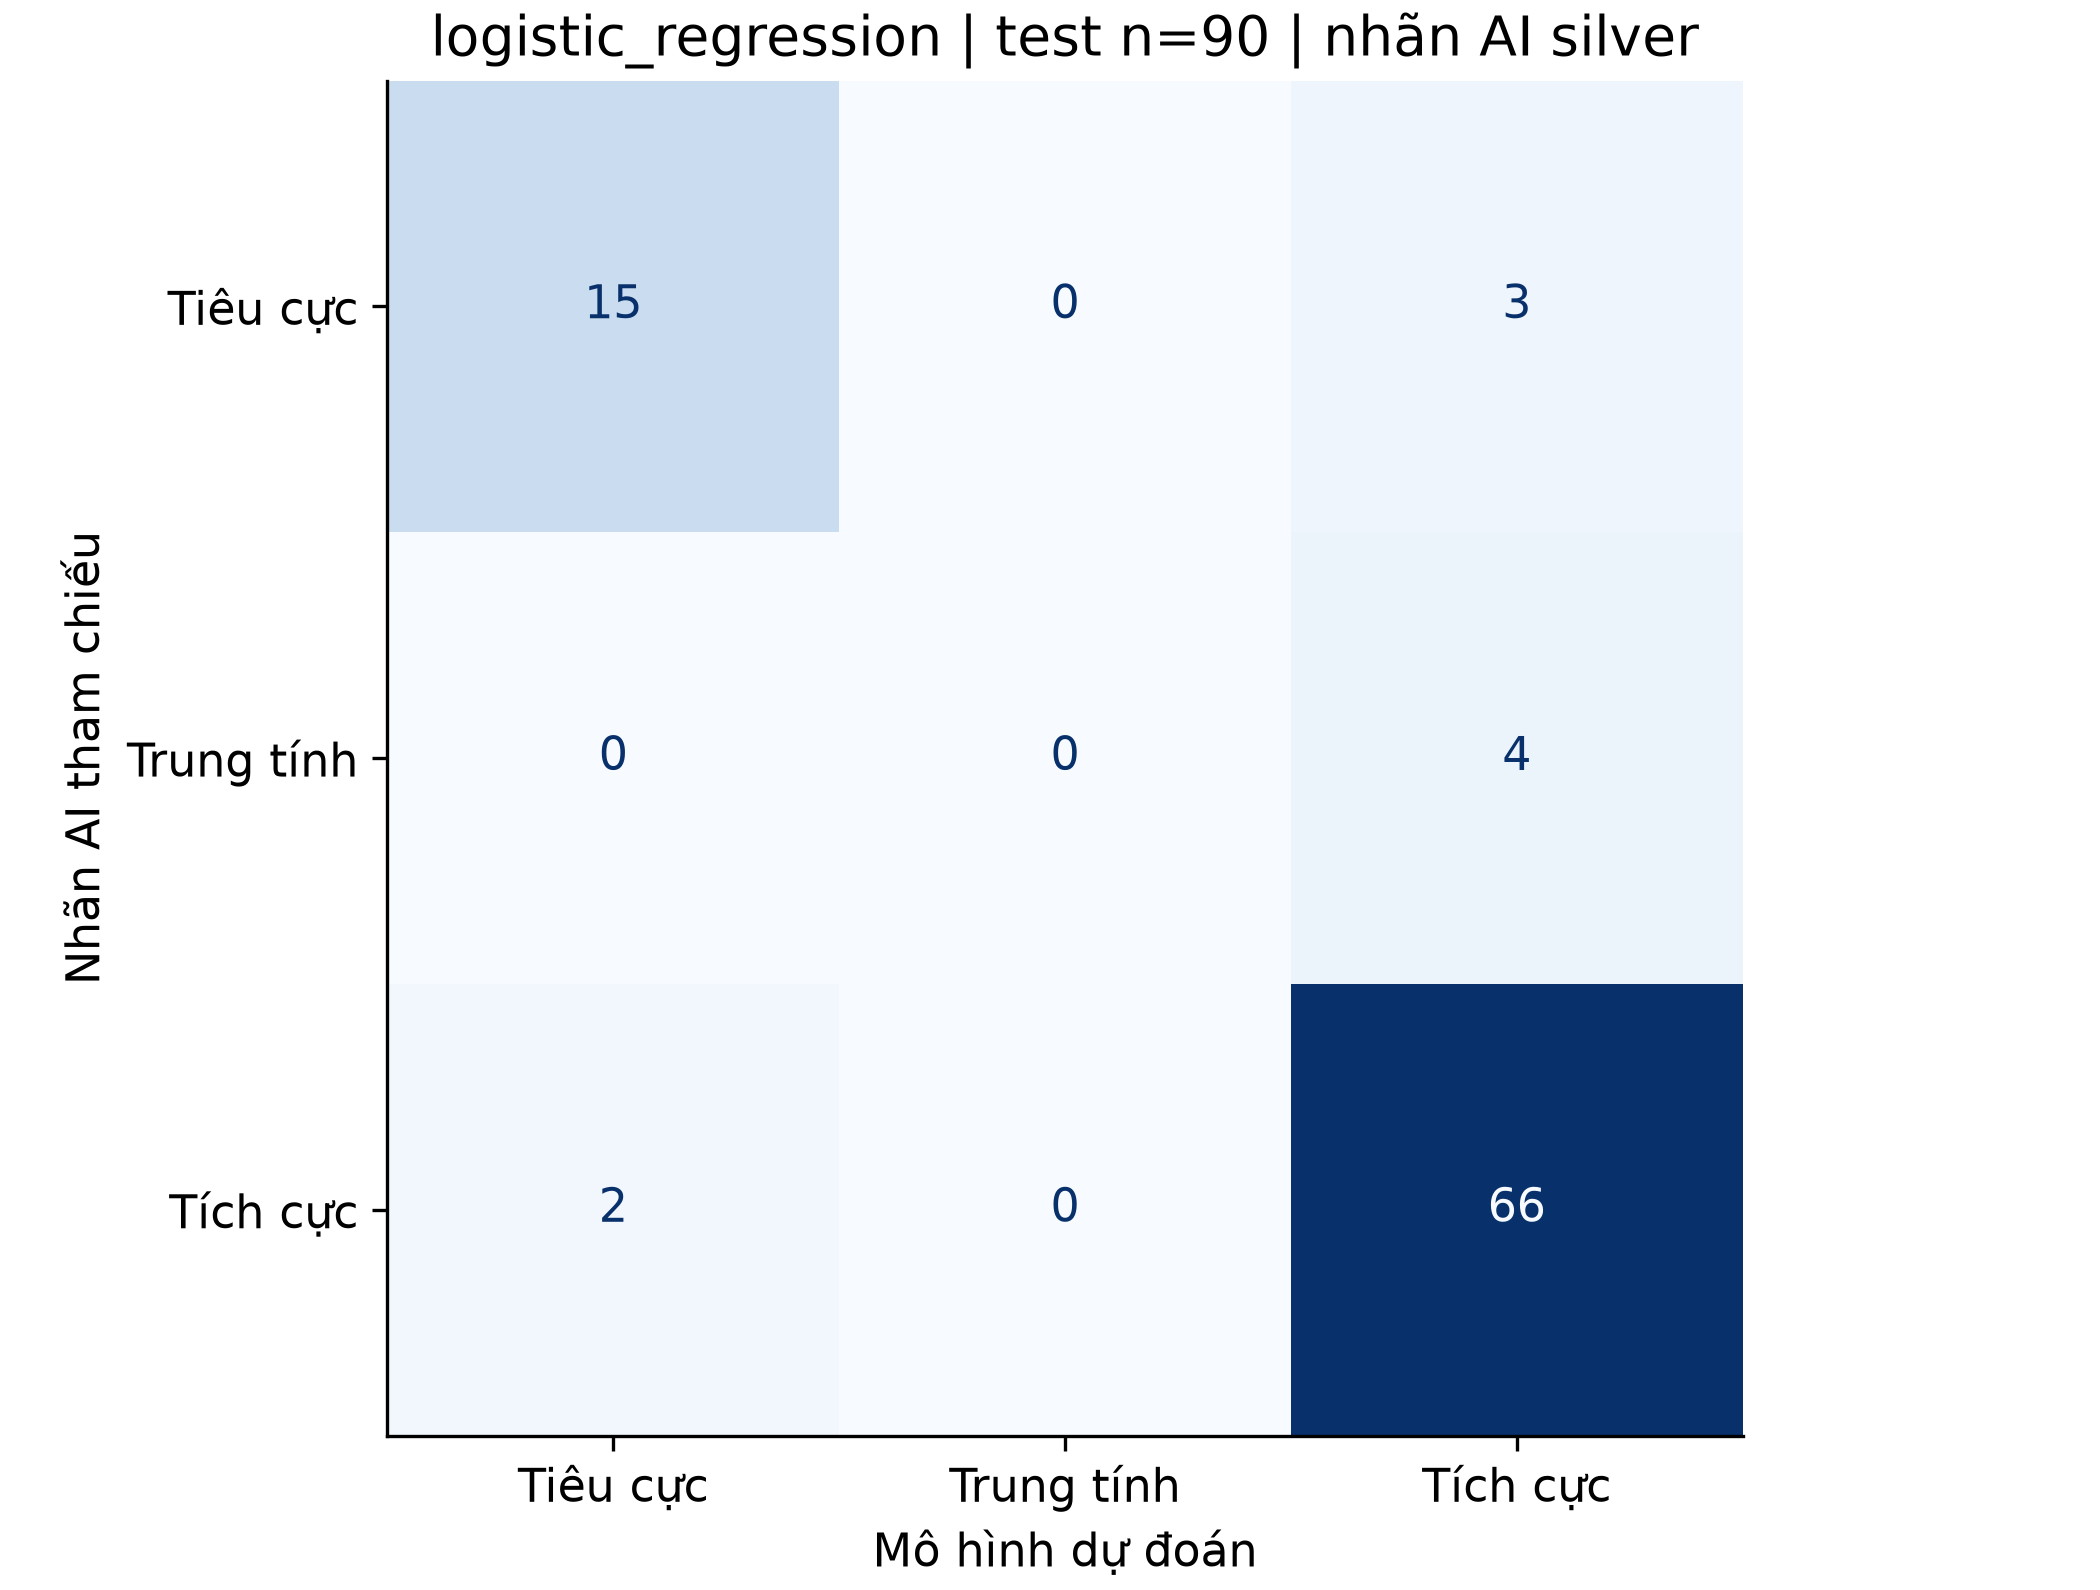

In [5]:
selected=manifest['selected_model']
test=manifest['test'][selected]
cm=np.array(test['confusion_matrix'])
tp=np.diag(cm);fp=cm.sum(axis=0)-tp;fn=cm.sum(axis=1)-tp
f1=np.divide(2*tp,2*tp+fp+fn,out=np.zeros(3,dtype=float),where=(2*tp+fp+fn)>0)
assert np.isclose(np.trace(cm)/cm.sum(),test['accuracy'])
assert np.isclose(f1.mean(),test['macro_f1'])
display(pd.DataFrame({'class':list(c.LABELS),'TP':tp,'FP':fp,'FN':fn,'F1':f1}))
print('accuracy=',tp.sum(),'/',cm.sum(),'=',test['accuracy'])
print('macro-F1=',f1.mean())
print('Bootstrap intervals:',test['bootstrap'])
display(Image(filename=str(OUT/'fig_class_confusion.png'),width=700))

## 5. Không để accuracy che lớp trung tính
Test có ít neutral và mô hình không dự đoán đúng lớp này. Accuracy 90% không có nghĩa giải quyết tốt cả ba lớp. CI bootstrap chỉ có điều kiện trên mẫu và rubric AI.

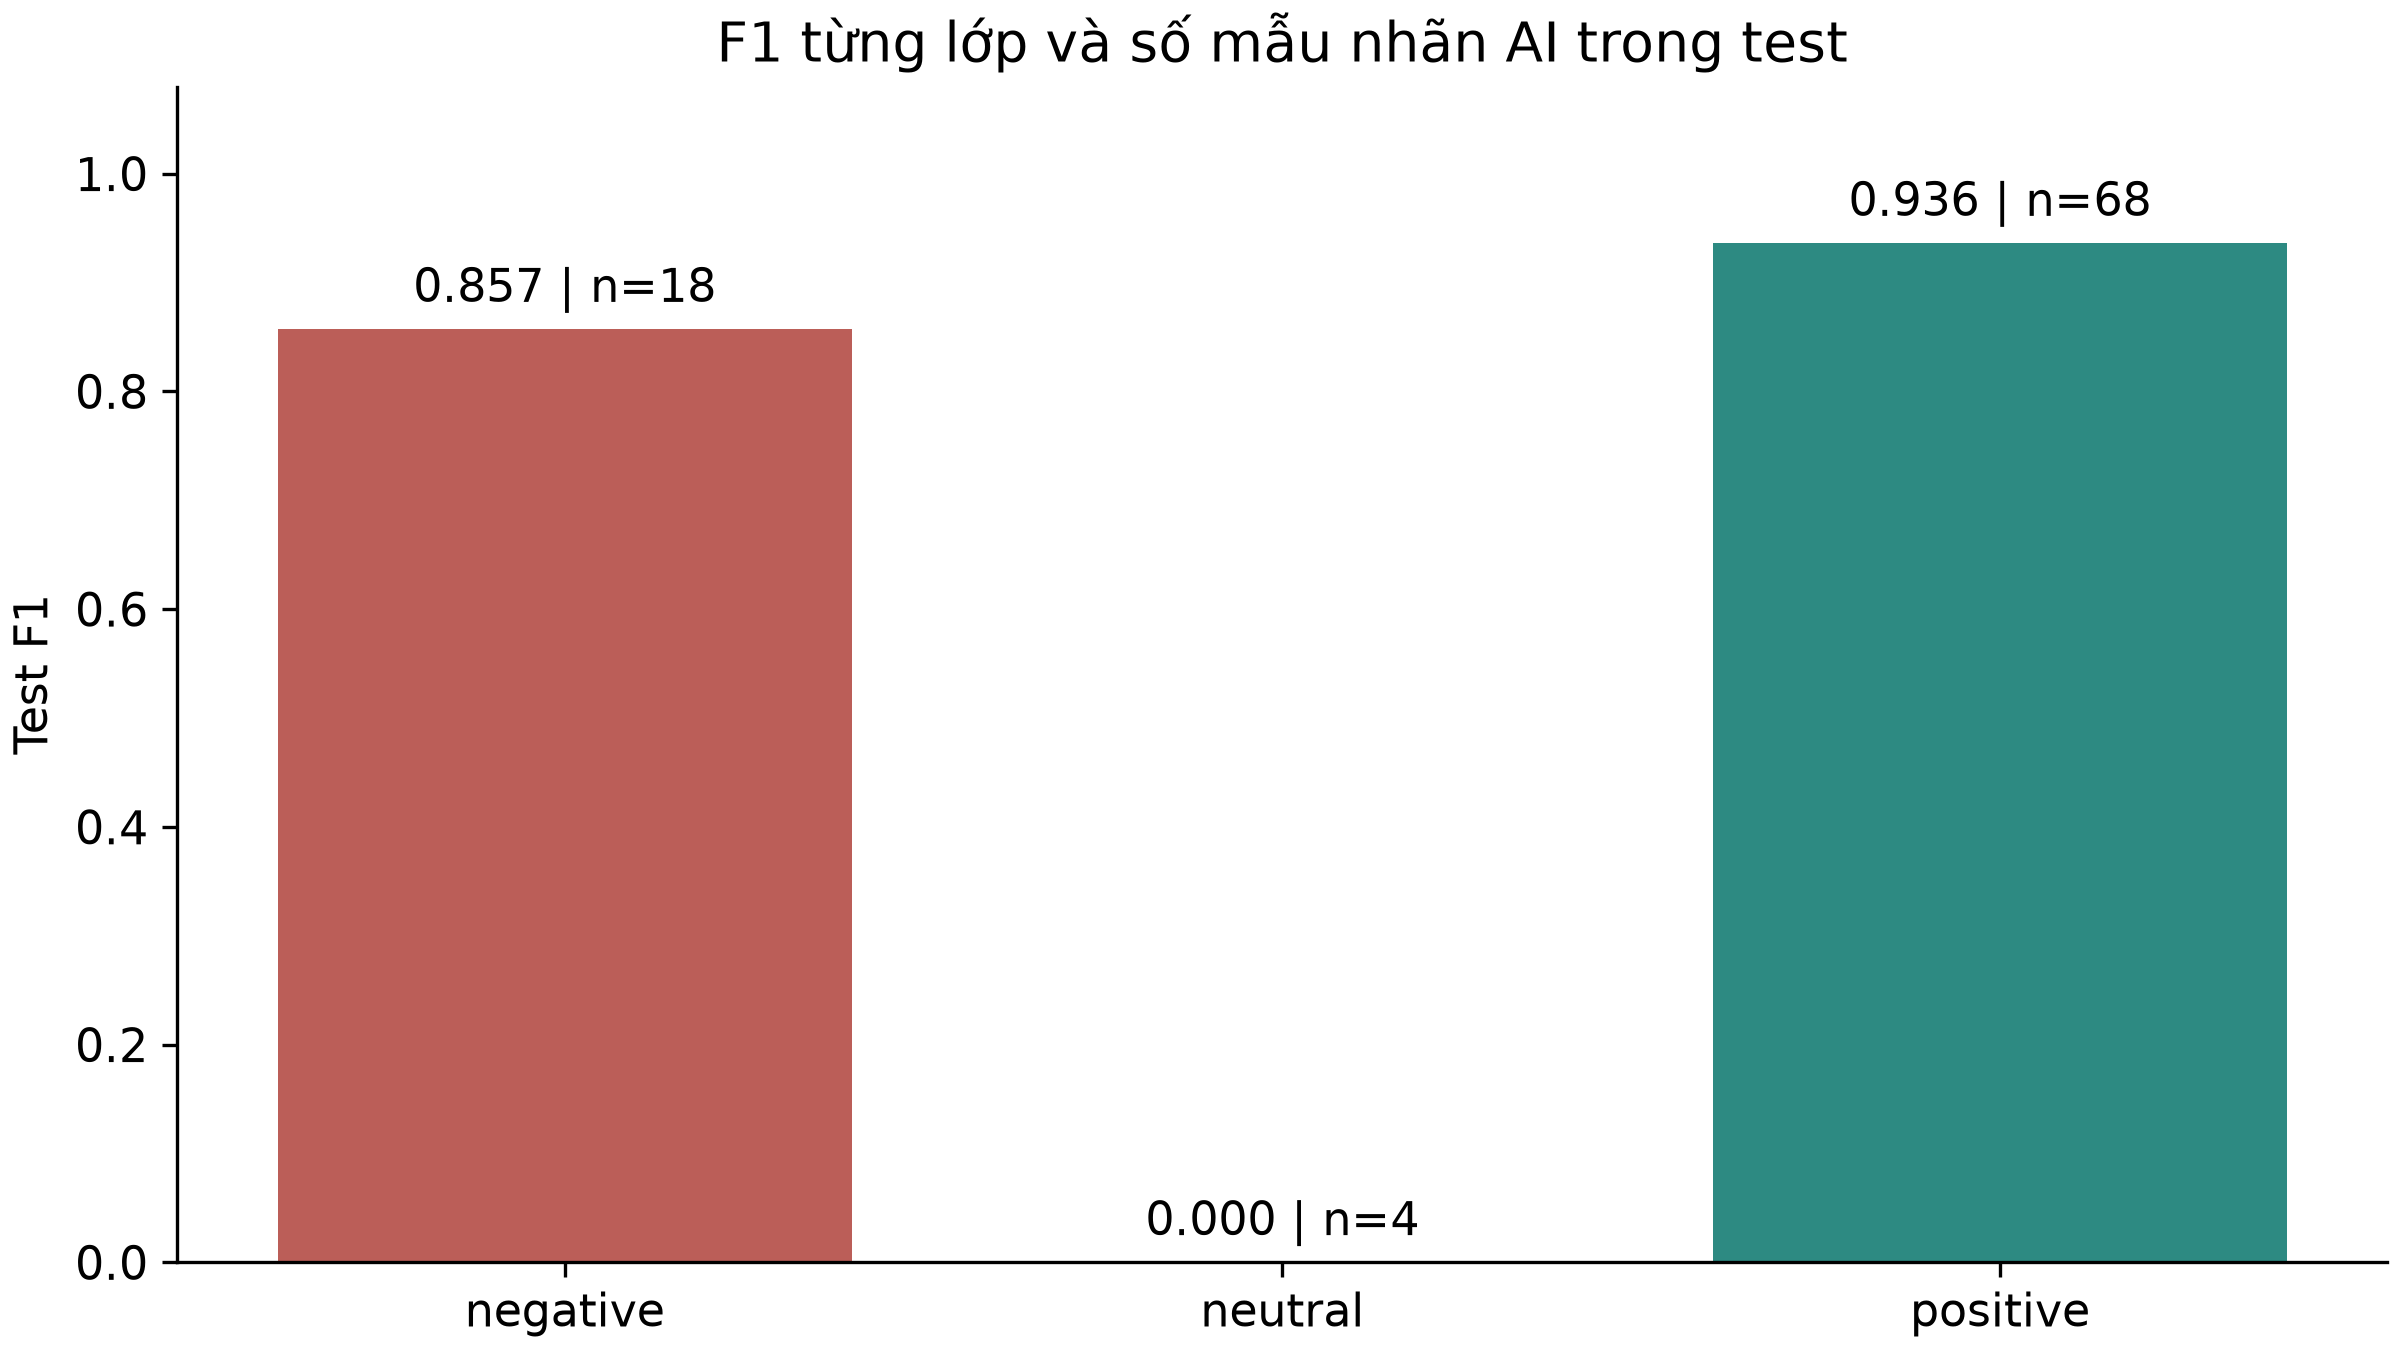

,field,value,n,accuracy,macro_f1_all_3_classes
0,source,Foody,47,0.893617,0.625649
1,source,Google Maps,43,0.906977,0.564286
2,region,Bắc,29,0.931034,0.651515
3,region,Nam,35,0.914286,0.583051
4,region,Trung,26,0.846154,0.554656
5,sentiment,negative,18,0.833333,0.303030
6,sentiment,neutral,4,0.000000,0.000000
7,sentiment,positive,68,0.970588,0.328358


,blind_id,text,sentiment,predicted_sentiment
1093,101,Không cho đá nên vị đậm đà hơn.,neutral,positive
1105,172,Có ai ship bây giờ k ạ?,neutral,positive
1107,188,Ăn combo một người. Cảm giác no kềnh càng. :))...,neutral,positive
1124,245,Làm nước quá chậm . Chờ muốn ngủ,negative,positive
1136,295,"Không khí yên tĩnh, nhẹ nhàng, 5 sao Tôi chưa ...",positive,negative
1151,377,"Mình tới quán này ăn 2-3 lần rồi, lên đồ ăn ba...",positive,negative
1155,389,"Quả bánh xèo to khủng khiếp, chắc 3 gái ăn là ...",neutral,positive
1157,405,"Nói chung là tệ luôn, đồ ăn không ngon, cá hấp...",negative,positive
1159,409,Không gian cũng ổn áp nhưng nói thật phần ăn c...,negative,positive


In [6]:
display(Image(filename=str(OUT/'fig_class_per_class.png'),width=800))
display(pd.read_csv(OUT/'test_strata.csv'))
pred=pd.read_csv(OUT/'predictions.csv')
errors=pred.loc[(pred.partition=='test')&(pred.model==selected)&~pred.correct]
display(errors[['blind_id','text','sentiment','predicted_sentiment']])

## 6. Từ khóa train và audit rating sau khi khóa nhãn
Log odds là liên hệ văn bản trên train, không phải hiệu ứng nhân quả hoặc độ quan trọng của mô hình. Rating chỉ được đối chiếu sau, không làm label hoặc feature.

In [7]:
display(pd.read_csv(OUT/'negative_keywords_train.csv').head(10))
rating=pd.read_csv(OUT/'rating_agreement_audit.csv')
print('AI vs rating heuristic agreement:',rating.agrees.mean(),'not human accuracy')

,term,negative_docs,other_docs,negative_total,other_total,smoothed_log_odds
0,tệ,13,0,51,219,5.036531
1,chậm,6,0,51,219,4.138589
2,chẳng,4,0,51,219,3.727847
3,kém,4,0,51,219,3.727847
4,quá tệ,4,0,51,219,3.727847
5,vẫn chưa,4,0,51,219,3.727847
6,đá,4,0,51,219,3.727847
7,khách hàng,3,0,51,219,3.455699
8,lỗi,3,0,51,219,3.455699
9,mình order,3,0,51,219,3.455699


AI vs rating heuristic agreement: 0.8111111111111111 not human accuracy


## 7. Tái lập bản báo cáo và kiểm tra leakage
So toàn bộ metrics/predictions/folds với bản nộp. Những review cùng nhóm phải ở một split.

In [8]:
BASE=ROOT/'report4_outputs/classification_20261115_final'
for filename in ['metrics_summary.csv','predictions.csv','sample_support.csv','cv_train_only.csv','rating_agreement_audit.csv']:
    pd.testing.assert_frame_equal(pd.read_csv(OUT/filename),pd.read_csv(BASE/filename))
rows=sum([c.read_rows(OUT/f'{split}.jsonl') for split in ['train','validation','test']],[])
c.check_splits(rows)
print('Reproduction and split checks passed.')

Reproduction and split checks passed.


## Kết luận và giới hạn
- Đã có đủ luồng gán nhãn AI có provenance, train/validation/test, hai classifier, Dummy và báo cáo thực nghiệm.
- Đánh giá chỉ đo mức khớp rubric AI; chưa có human gold hay kappa độc lập.
- Tập source-region cân bằng, review 20-300 ký tự, loại mixed: không đại diện mọi review, không suy rộng tỷ lệ cảm xúc toàn khách hàng.
- Mẫu nhỏ và neutral ít; cần nhãn người, thêm neutral/mixed và test mới cho vòng cải tiến. Không sửa nhãn theo lỗi test để tăng điểm.